
# SKIN DISORDER PREDICTION
## PRCP-1027 – Certified Data Scientist Capstone Project

### 1. Project Overview

The objective of this project is to analyse dermatological data and develop machine learning models to predict different classes of erythemato-squamous skin diseases.

### 2. Problem Statement

To perform exploratory data analysis, preprocess the dataset, develop predictive machine learning models, compare their performance, and provide suggestions to doctors for early identification of skin diseases.

### 3. Project Objectives

- Perform complete data analysis.
- Identify important clinical and histopathological features.
- Develop multiple machine learning classification models.
- Compare model performance.
- Select the most suitable model.
- Provide recommendations for early disease identification.
- Document challenges faced during the project.

### 4. Domain

Healthcare – Dermatology


In [1]:
print("PRCP-1027: Skin Disorder Prediction")
print("Certified Data Scientist Capstone Project")
print("Environment setup successful!")

PRCP-1027: Skin Disorder Prediction
Certified Data Scientist Capstone Project
Environment setup successful!


In [2]:
import os

# Check current working directory
print("Current Working Directory:")
print(os.getcwd())

# List files and folders
print("\nAvailable files and folders:")
print(os.listdir())

Current Working Directory:
/Users/haarshini/Documents/PRCP_1027_Skin_Disorder

Available files and folders:
['.DS_Store', 'anaconda_projects', 'Dataset', '.ipynb_checkpoints', 'PRCP_1027_Skin_Disorder_Prediction.ipynb.zip', 'PRCP_1027_Skin_Disorder_Prediction.ipynb', 'Outputs']


In [3]:
import os

print("Does Dataset folder exist?", os.path.exists("Dataset"))

if os.path.exists("Dataset"):
    print("\nFiles inside Dataset:")
    print(os.listdir("Dataset"))

Does Dataset folder exist? True

Files inside Dataset:
['PRCP-1028-Skin-Disorder-Prediction-20220512T101734Z-001.zip', '.DS_Store', 'PRCP-1028-Skin-Disorder-Prediction']


In [4]:
import os

folder_path = "Dataset/PRCP-1028-Skin-Disorder-Prediction"

print("Files inside extracted folder:")
print(os.listdir(folder_path))

Files inside extracted folder:
['dataset_35_dermatology (1).csv']


In [5]:
import pandas as pd
import numpy as np

# Define dataset path
file_path = "Dataset/PRCP-1028-Skin-Disorder-Prediction/dataset_35_dermatology (1).csv"

# Load dataset
df = pd.read_csv(file_path, header=None, na_values="?")

# Display first five records
df.head()

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
1,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
2,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
3,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
4,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1


In [6]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Number of duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (367, 35)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 35 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       367 non-null    str  
 1   1       367 non-null    str  
 2   2       367 non-null    str  
 3   3       367 non-null    str  
 4   4       367 non-null    str  
 5   5       367 non-null    str  
 6   6       367 non-null    str  
 7   7       367 non-null    str  
 8   8       367 non-null    str  
 9   9       367 non-null    str  
 10  10      367 non-null    str  
 11  11      367 non-null    str  
 12  12      367 non-null    str  
 13  13      367 non-null    str  
 14  14      367 non-null    str  
 15  15      367 non-null    str  
 16  16      367 non-null    str  
 17  17      367 non-null    str  
 18  18      367 non-null    str  
 19  19      367 non-null    str  
 20  20      367 non-null    str  
 21  21      367 non-null    str  
 22  22      367 no

In [7]:
# Display the first 5 rows
display(df.head())

# Display the first row separately
print("\nFirst row of the dataset:")
print(df.iloc[0].tolist())

# Display the last 5 rows
display(df.tail())

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
1,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
2,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
3,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
4,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1



First row of the dataset:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_in_the_infiltrate', 'PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_of_the_granular_layer', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw-tooth_appearance_of_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate', 'band-like_infiltrate', 'Age', 'class']


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
362,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
363,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
364,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
365,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
366,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [8]:
# Check unique values in the first column
print(df[0].unique()[:15])

# Check unique values in the last column
print(df[34].unique())

<StringArray>
['erythema', '2', '3', '1', '0']
Length: 5, dtype: str
<StringArray>
['class', '2', '1', '3', '5', '4', '6']
Length: 7, dtype: str


In [9]:
# Load dataset with correct column names

df = pd.read_csv(
    file_path,
    header=0,
    na_values="?"
)

# Display first five records
display(df.head())

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [10]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (366, 35)

Column Names:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_in_the_infiltrate', 'PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_of_the_granular_layer', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw-tooth_appearance_of_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate', 'band-like_infiltrate', 'Age', 'class']

Data Types:
erythema                                      int64
scaling                                       int64
definite_bor

In [11]:
print("Disease Class Distribution:")
print(df["class"].value_counts().sort_index())

Disease Class Distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


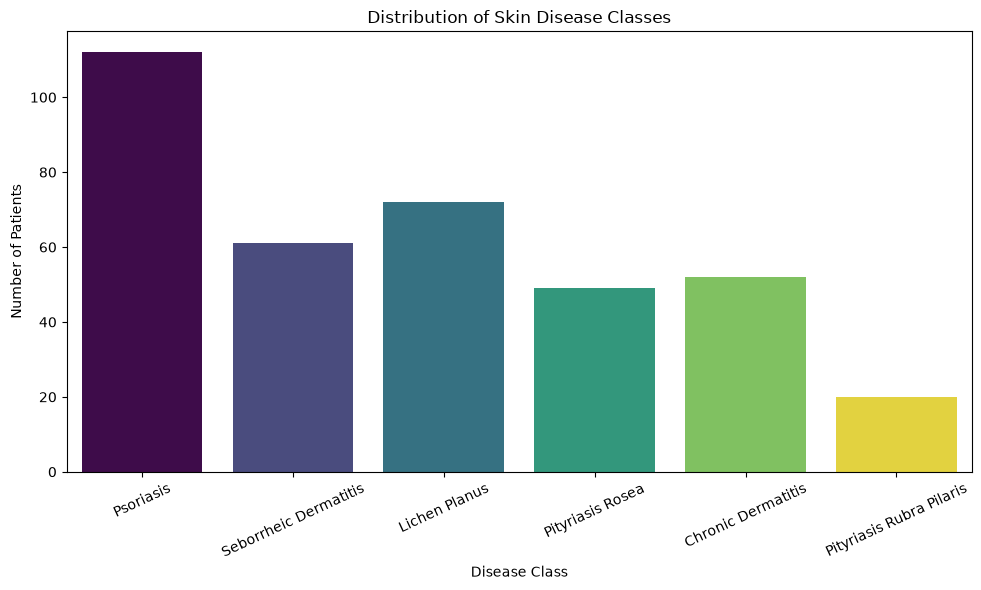

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Disease class distribution
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="class",
    hue="class",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Skin Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Patients")
plt.xticks([0, 1, 2, 3, 4, 5],
           ["Psoriasis", "Seborrheic Dermatitis",
            "Lichen Planus", "Pityriasis Rosea",
            "Chronic Dermatitis", "Pityriasis Rubra Pilaris"],
           rotation=25)

plt.tight_layout()
plt.show()


### Interpretation of Disease Class Distribution

The bar graph illustrates the distribution of six different skin disease classes in the dermatology dataset.

Psoriasis (Class 1) has the highest number of observations, with 112 patients, followed by Lichen Planus (Class 3), with 72 patients.

Pityriasis Rubra Pilaris (Class 6) has the lowest number of observations, with only 20 patients.

The distribution indicates class imbalance, which may affect the performance of machine learning classification models. Therefore, appropriate evaluation metrics such as precision, recall and macro F1-score will be considered during model comparison.


In [13]:
# Calculate disease class percentages

class_counts = df["class"].value_counts().sort_index()

class_percentage = (
    df["class"].value_counts(normalize=True).sort_index() * 100
)

distribution = pd.DataFrame({
    "Patient_Count": class_counts,
    "Percentage": class_percentage
})

display(distribution.round(2))

,Patient_Count,Percentage
class,,
1,112,30.60
2,61,16.67
3,72,19.67
4,49,13.39
5,52,14.21
6,20,5.46


In [14]:
# Check missing values in each column

missing_data = df.isnull().sum()

missing_data = missing_data[missing_data > 0]

print("Columns containing missing values:")
print(missing_data)

Columns containing missing values:
Age    8
dtype: int64


In [15]:
# Convert all columns into numeric format

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Check data types
print("Updated Data Types:")
print(df.dtypes)

# Check dataset information
df.info()

Updated Data Types:
erythema                                      int64
scaling                                       int64
definite_borders                              int64
itching                                       int64
koebner_phenomenon                            int64
polygonal_papules                             int64
follicular_papules                            int64
oral_mucosal_involvement                      int64
knee_and_elbow_involvement                    int64
scalp_involvement                             int64
family_history                                int64
melanin_incontinence                          int64
eosinophils_in_the_infiltrate                 int64
PNL_infiltrate                                int64
fibrosis_of_the_papillary_dermis              int64
exocytosis                                    int64
acanthosis                                    int64
hyperkeratosis                                int64
parakeratosis                               

In [16]:
# Statistical summary of Age

print("Age Column Statistics:")
print(df["Age"].describe())

# Check missing Age values
print("\nMissing Age Values:", df["Age"].isnull().sum())

# Calculate median age
print("\nMedian Age:", df["Age"].median())

Age Column Statistics:
count    358.000000
mean      36.296089
std       15.324557
min        0.000000
25%       25.000000
50%       35.000000
75%       49.750000
max       75.000000
Name: Age, dtype: float64

Missing Age Values: 8

Median Age: 35.0


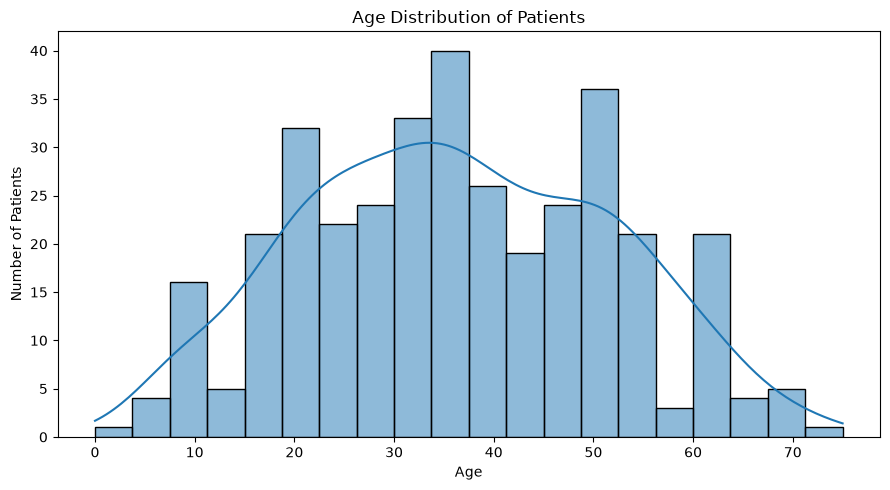

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(df["Age"].dropna(), bins=20, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()



### Age Distribution Analysis

The age distribution of patients was analysed using a histogram and descriptive statistics.

The dataset contains 358 valid age observations, with 8 missing values.

The mean age is 36.30 years, while the median age is 35 years. The standard deviation is 15.32 years, indicating variation in the age distribution.

The minimum recorded age is 0 years and the maximum is 75 years.

The median age will be considered for missing value imputation after examining the age distribution and unusual values.


In [18]:
# Check frequency of each age

print("Age Value Counts:")
print(df["Age"].value_counts().sort_index())

# Check records with age equal to zero
print("\nRecords with Age = 0:")
display(df[df["Age"] == 0])

Age Value Counts:
Age
0.0      1
7.0      4
8.0      7
9.0      2
10.0     7
12.0     3
13.0     2
15.0     2
16.0     5
17.0     5
18.0     9
19.0     6
20.0     8
21.0     3
22.0    15
23.0     3
24.0     2
25.0    14
26.0     3
27.0    16
28.0     5
29.0     3
30.0    13
31.0     2
32.0     6
33.0    12
34.0     8
35.0    14
36.0    16
37.0     2
38.0     3
39.0     2
40.0    17
41.0     4
42.0    10
43.0     4
44.0     5
45.0     7
46.0     6
47.0     6
48.0     5
49.0     1
50.0    17
51.0     7
52.0    11
53.0     2
55.0    14
56.0     5
57.0     2
58.0     1
60.0    11
61.0     2
62.0     7
63.0     1
64.0     1
65.0     2
67.0     1
68.0     1
70.0     4
75.0     1
Name: count, dtype: int64

Records with Age = 0:


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
119,1,1,1,1,1,0,0,0,2,2,...,0,0,0,0,0,0,0,2,0.0,1


In [19]:
# Create a copy for exploratory analysis

df_eda = df.copy()

# Calculate median age
median_age = df_eda["Age"].median()

# Fill missing age values in the EDA copy
df_eda["Age"] = df_eda["Age"].fillna(median_age)

print("Missing Age Values Before:", df["Age"].isnull().sum())
print("Missing Age Values After:", df_eda["Age"].isnull().sum())

print("Median Used:", median_age)

Missing Age Values Before: 8
Missing Age Values After: 0
Median Used: 35.0


In [20]:
# Check patients with age equal to zero

zero_age_records = df[df["Age"] == 0]

print("Number of patients with Age = 0:",
      len(zero_age_records))

display(zero_age_records)

Number of patients with Age = 0: 1


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
119,1,1,1,1,1,0,0,0,2,2,...,0,0,0,0,0,0,0,2,0.0,1


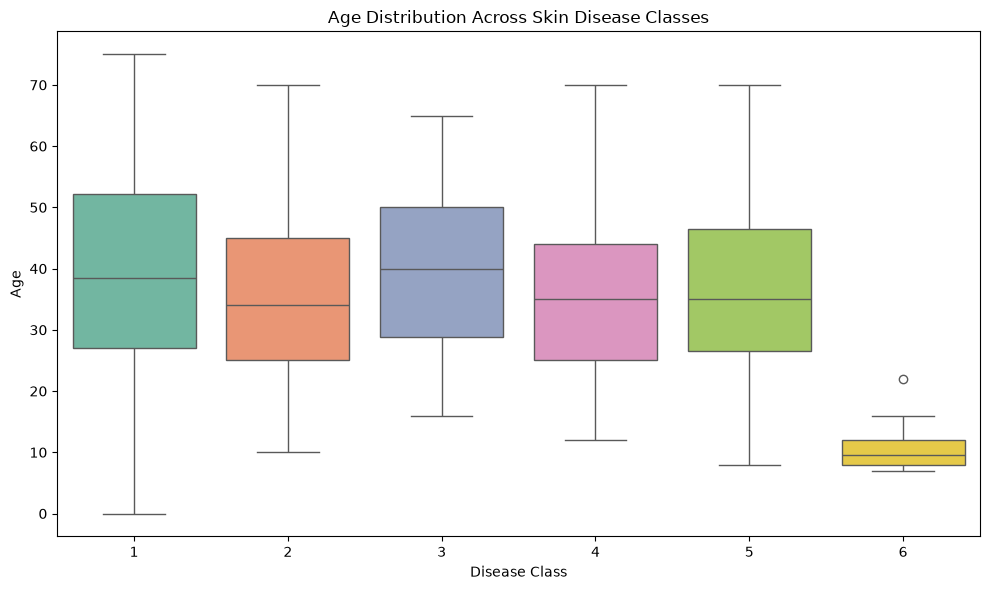

In [21]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_eda,
    x="class",
    y="Age",
    hue="class",
    palette="Set2",
    legend=False
)

plt.title("Age Distribution Across Skin Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

In [22]:
# Identify records with age equal to zero

zero_age_records = df[df["Age"] == 0]

print("Number of records with Age = 0:",
      len(zero_age_records))

display(zero_age_records)

Number of records with Age = 0: 1


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
119,1,1,1,1,1,0,0,0,2,2,...,0,0,0,0,0,0,0,2,0.0,1


In [23]:
# Check age statistics for each disease class

age_summary = df_eda.groupby("class")["Age"].describe()

display(age_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
1,112.0,39.34,15.59,0.0,27.00,38.5,52.25,75.0
2,61.0,35.46,13.47,10.0,25.00,34.0,45.00,70.0
3,72.0,39.89,11.69,16.0,28.75,40.0,50.00,65.0
4,49.0,35.27,13.82,12.0,25.00,35.0,44.00,70.0
5,52.0,36.54,14.84,8.0,26.50,35.0,46.50,70.0
6,20.0,10.25,3.71,7.0,8.00,9.5,12.00,22.0


In [24]:
# Inspect patient record 119

print("Patient Record 119:")
display(df.loc[[119]].T)

Patient Record 119:


,119
erythema,1.0
scaling,1.0
definite_borders,1.0
itching,1.0
koebner_phenomenon,1.0
polygonal_papules,0.0
follicular_papules,0.0
oral_mucosal_involvement,0.0
knee_and_elbow_involvement,2.0
scalp_involvement,2.0


In [25]:
# Calculate missing values in every column

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

display(missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
))

,Missing_Count,Missing_Percentage
Age,8,2.185792


In [26]:
# Identify unexpected values in clinical and histopathological features

feature_columns = df.columns.drop(["Age", "class"])

for column in feature_columns:
    invalid_values = df.loc[
        ~df[column].isin([0, 1, 2, 3]) & df[column].notna(),
        column
    ]

    if len(invalid_values) > 0:
        print(column, invalid_values.unique())

In [27]:
# Check whether clinical and histopathological values
# fall within the expected range of 0 to 3

feature_columns = df.columns.drop(["Age", "class"])

for column in feature_columns:
    invalid = df[
        ~df[column].isin([0, 1, 2, 3]) & df[column].notna()
    ]

    if not invalid.empty:
        print(column, invalid[column].unique())

print("Feature range validation completed.")

Feature range validation completed.


In [28]:
print(df.loc[119, ["Age", "class"]])

Age      0.0
class    1.0
Name: 119, dtype: float64


In [29]:
feature_columns = df.columns.drop(["Age", "class"])

invalid_records = {}

for column in feature_columns:
    invalid = df.loc[
        ~df[column].isin([0, 1, 2, 3]) & df[column].notna(),
        column
    ]

    if not invalid.empty:
        invalid_records[column] = invalid.unique()

print("Invalid feature values:", invalid_records)

Invalid feature values: {}


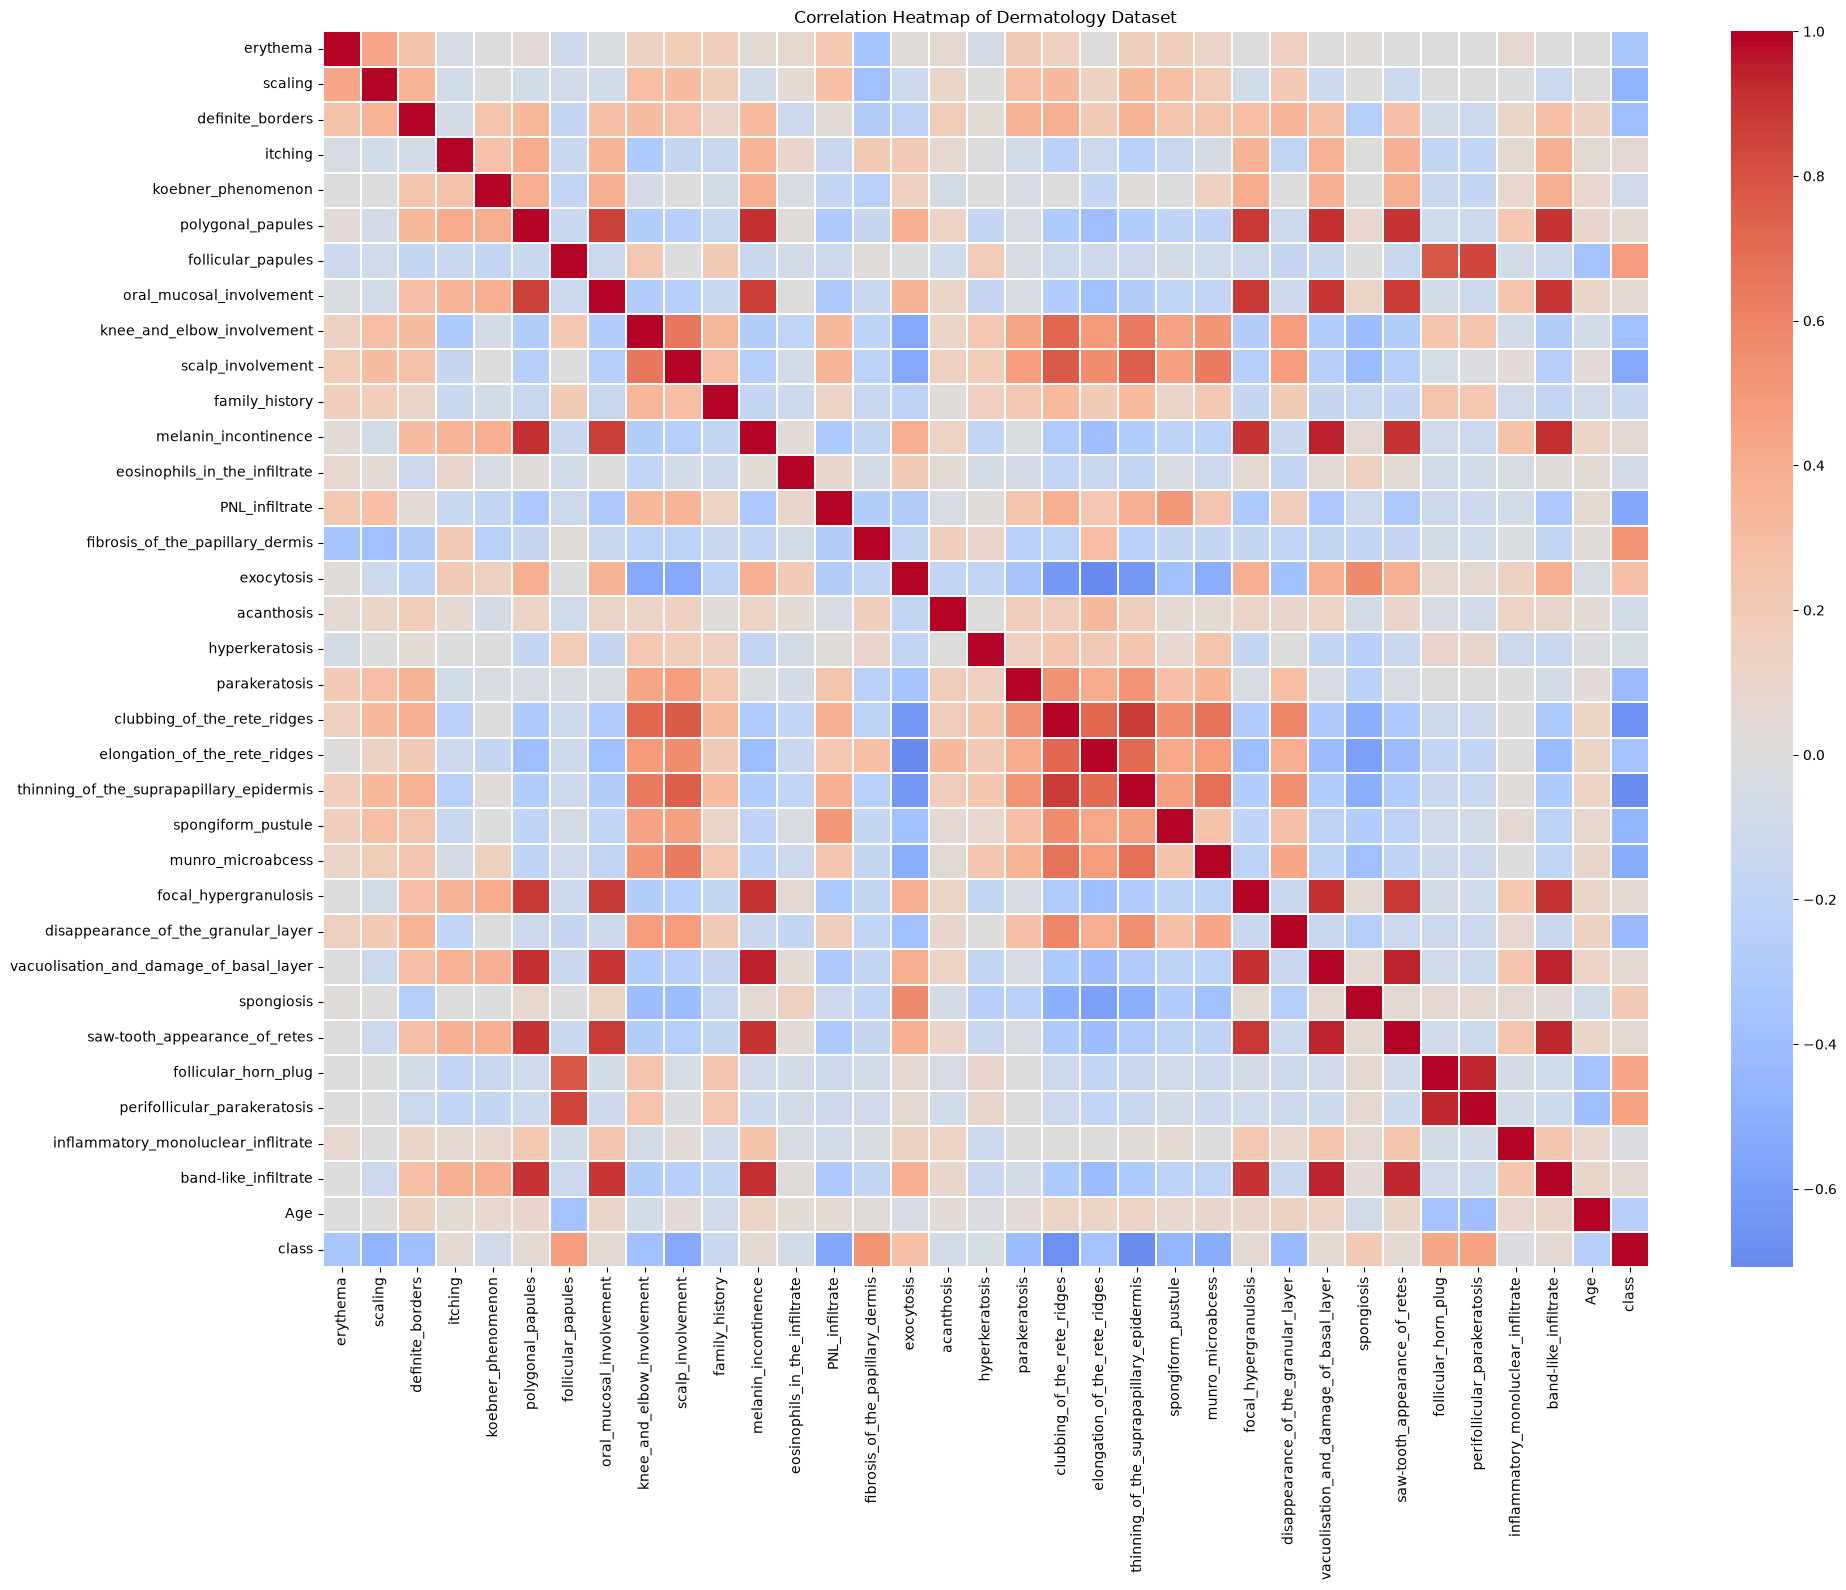

In [30]:
# Calculate correlation matrix

correlation_matrix = df_eda.corr()

# Display correlation heatmap

plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Dermatology Dataset")
plt.tight_layout()
plt.show()

In [31]:
%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [32]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Installation successful!")

Scikit-learn version: 1.9.1
Installation successful!


In [33]:
from sklearn.feature_selection import mutual_info_classif

X_mi = df_eda.drop(columns=["class"])
y_mi = df_eda["class"]

mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI_Score": mi_scores
})

mi_results = mi_results.sort_values(
    by="MI_Score",
    ascending=False
)

display(mi_results)

,Feature,MI_Score
20,elongation_of_the_rete_ridges,0.578766
19,clubbing_of_the_rete_ridges,0.568074
21,thinning_of_the_suprapapillary_epidermis,0.534654
28,saw-tooth_appearance_of_retes,0.503324
11,melanin_incontinence,0.499348
32,band-like_infiltrate,0.491631
24,focal_hypergranulosis,0.478665
26,vacuolisation_and_damage_of_basal_layer,0.462895
7,oral_mucosal_involvement,0.415473
5,polygonal_papules,0.411888


In [34]:
from sklearn.feature_selection import mutual_info_classif

# Separate input features and target
X_mi = df_eda.drop(columns=["class"])
y_mi = df_eda["class"]

# 33 ordinal/discrete features and 1 continuous feature (Age)
discrete_mask = [True] * 33 + [False]

# Calculate mutual information
mi_scores_corrected = mutual_info_classif(
    X_mi,
    y_mi,
    discrete_features=discrete_mask,
    random_state=42
)

# Create feature importance table
mi_results = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI_Score": mi_scores_corrected
})

mi_results = mi_results.sort_values(
    by="MI_Score",
    ascending=False
).reset_index(drop=True)

display(mi_results)

,Feature,MI_Score
0,elongation_of_the_rete_ridges,0.598274
1,clubbing_of_the_rete_ridges,0.550450
2,thinning_of_the_suprapapillary_epidermis,0.546579
3,band-like_infiltrate,0.486418
4,saw-tooth_appearance_of_retes,0.475650
5,vacuolisation_and_damage_of_basal_layer,0.474994
6,melanin_incontinence,0.463070
7,focal_hypergranulosis,0.460865
8,polygonal_papules,0.450003
9,exocytosis,0.429934


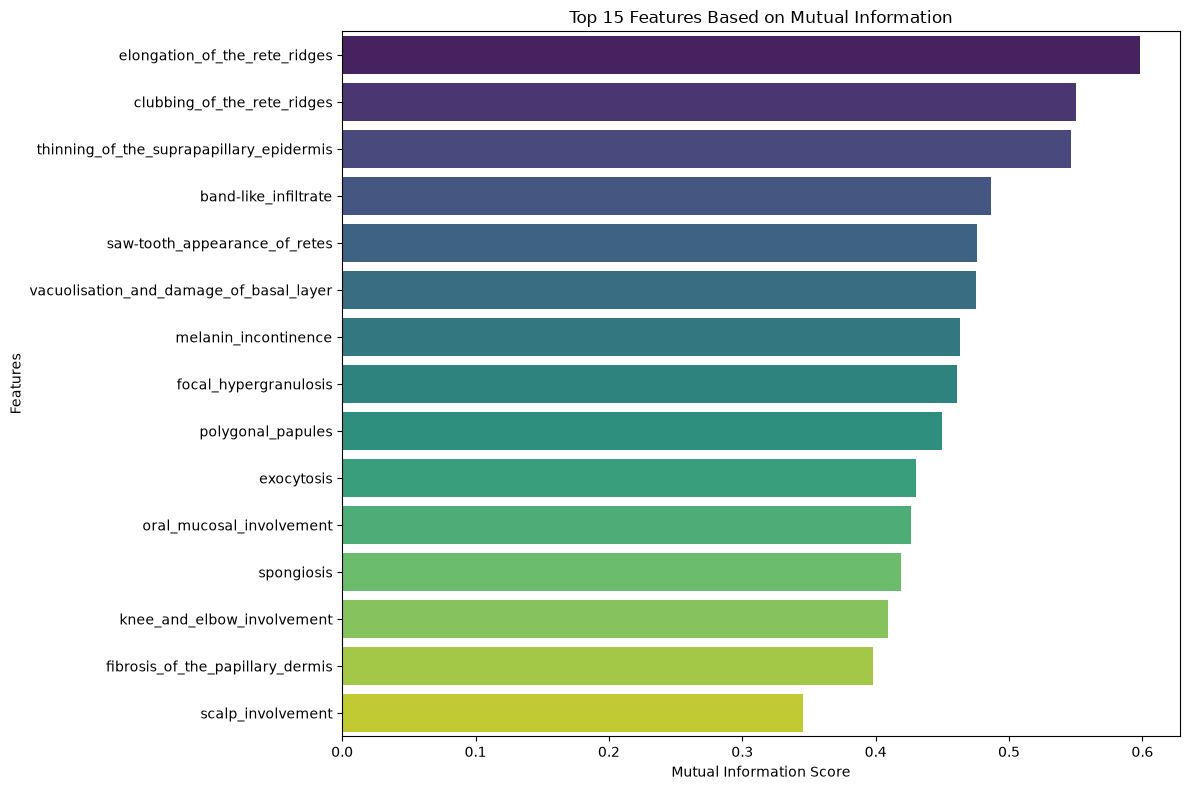

In [35]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=mi_results.head(15),
    x="MI_Score",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Features Based on Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [36]:
# Separate independent and dependent variables

X = df.drop(columns=["class"])
y = df["class"]

# Display dimensions

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nTarget Classes:")
print(y.unique())

Input Features (X): (366, 34)
Target Variable (y): (366,)

Target Classes:
[2 1 3 5 4 6]


In [37]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (292, 34)
Testing Features: (74, 34)
Training Target: (292,)
Testing Target: (74,)


In [38]:
print("Training Set Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Set Class Distribution:")
print(y_test.value_counts().sort_index())

Training Set Class Distribution:
class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64

Testing Set Class Distribution:
class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64


In [39]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Preprocessing pipeline

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fit only on training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_scaled = preprocessor.transform(X_test)

print("Training preprocessing shape:", X_train_scaled.shape)
print("Testing preprocessing shape:", X_test_scaled.shape)

print("\nRemaining missing values in training:",
      np.isnan(X_train_scaled).sum())

print("Remaining missing values in testing:",
      np.isnan(X_test_scaled).sum())

Training preprocessing shape: (292, 34)
Testing preprocessing shape: (74, 34)

Remaining missing values in training: 0
Remaining missing values in testing: 0


In [40]:
# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [41]:
# Define machine learning models

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ])
}

print("Five machine learning models are ready!")

Five machine learning models are ready!


In [42]:
# Train the models

trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "training completed!")

Logistic Regression training completed!
Decision Tree training completed!
Random Forest training completed!
KNN training completed!
SVM training completed!


In [43]:
# Store model performance

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1_Macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

model_results = pd.DataFrame(results)

display(
    model_results.sort_values(
        by="F1_Macro",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
4,SVM,0.9730,0.9722,0.9722,0.9697
0,Logistic Regression,0.9595,0.9615,0.9611,0.9574
1,Decision Tree,0.9595,0.9364,0.9611,0.9447
2,Random Forest,0.9459,0.9197,0.9417,0.9274
3,KNN,0.9054,0.9071,0.9094,0.9034


In [44]:
for name, model in trained_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[1, 2, 3, 4, 5, 6],
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74


MODEL: Decision Tree
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.91      1.00      0.95        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy               

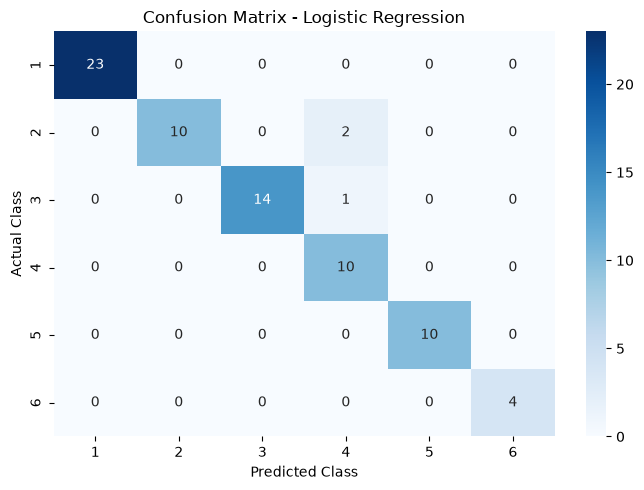

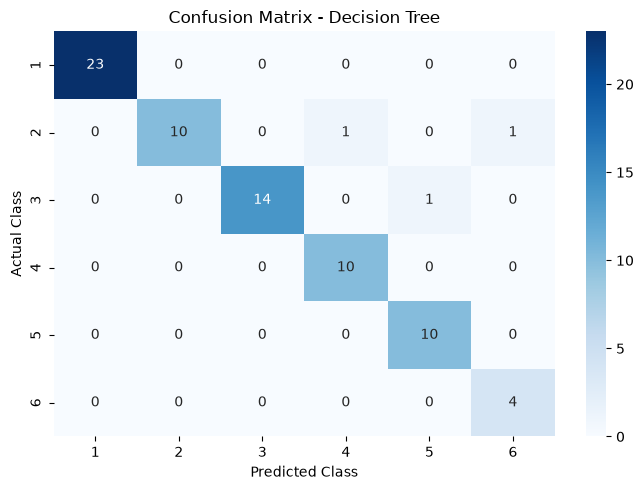

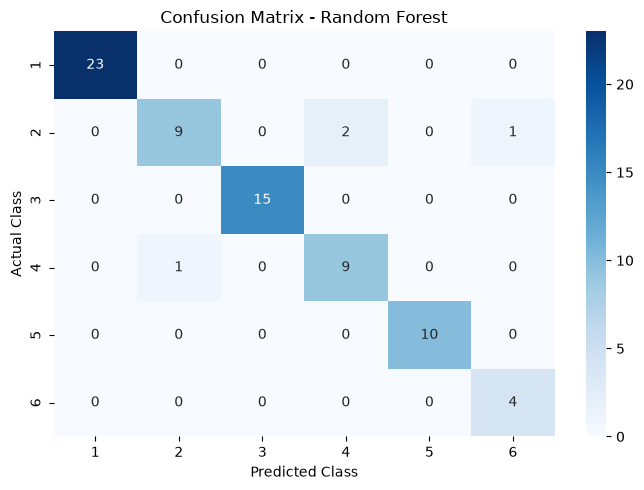

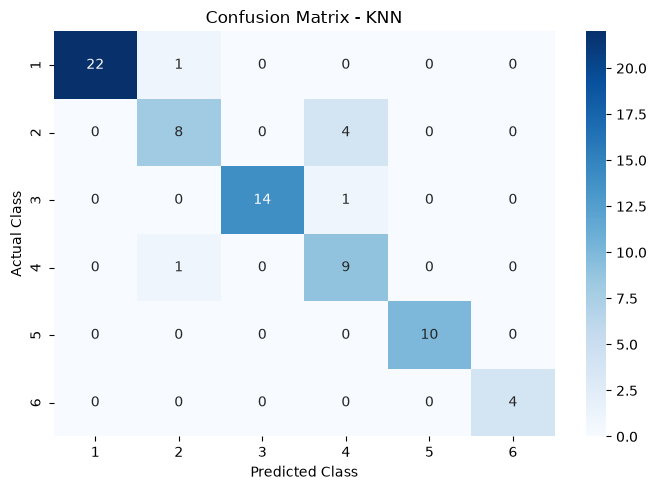

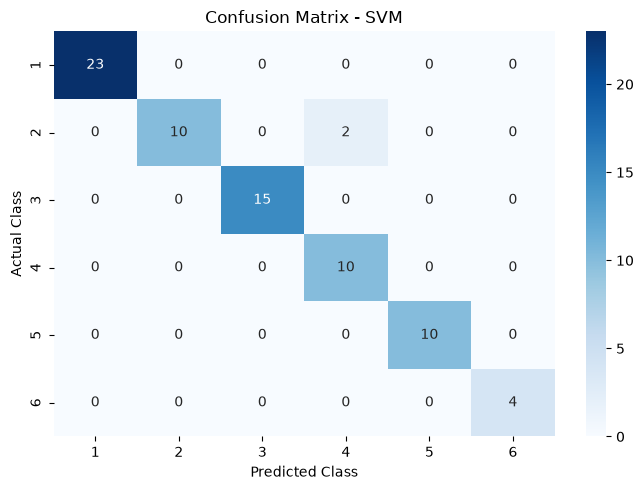

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3, 4, 5, 6]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[1, 2, 3, 4, 5, 6],
        yticklabels=[1, 2, 3, 4, 5, 6]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

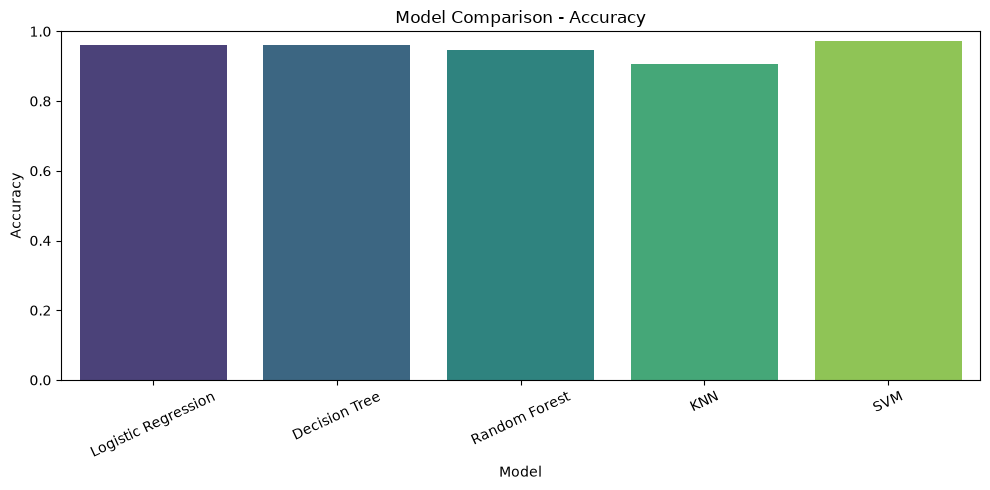

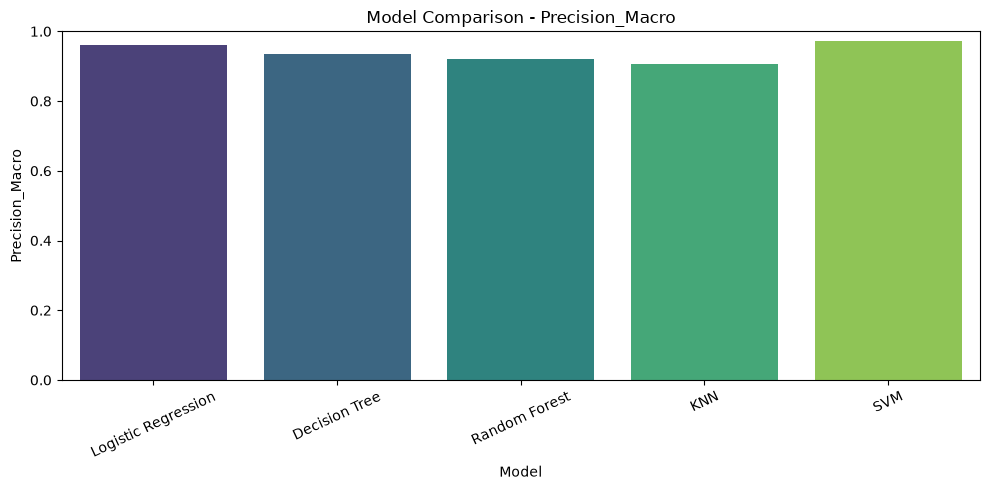

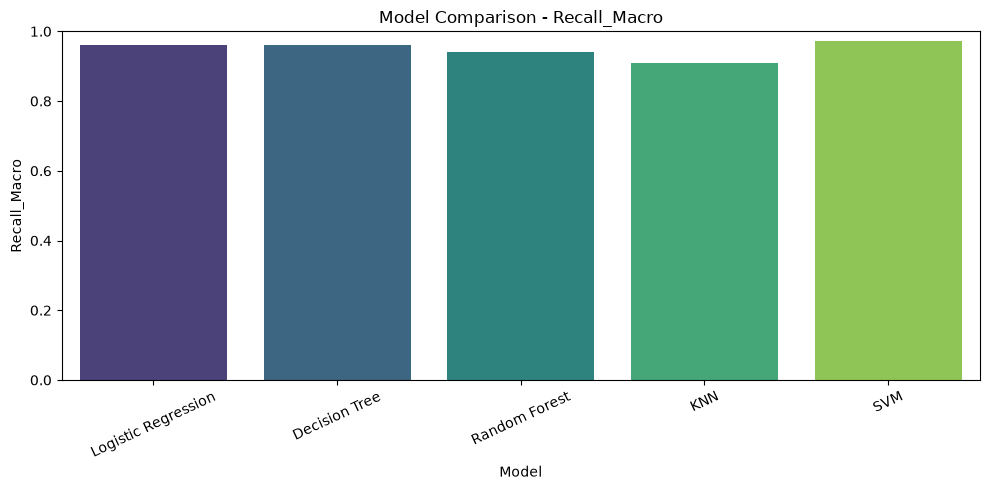

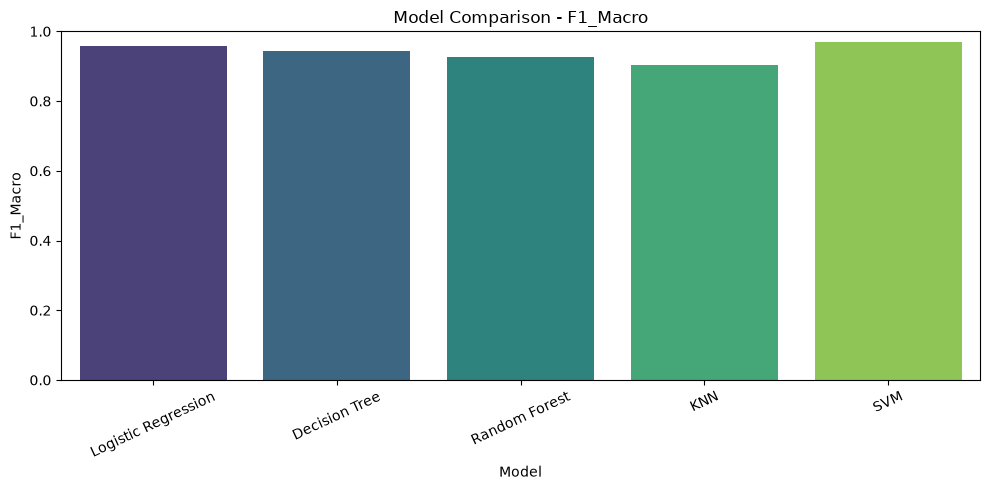

In [46]:
metrics = ["Accuracy", "Precision_Macro",
           "Recall_Macro", "F1_Macro"]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=model_results,
        x="Model",
        y=metric,
        hue="Model",
        palette="viridis",
        legend=False
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=25)
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="f1_macro"
    )

    cv_results.append({
        "Model": name,
        "Mean_F1": scores.mean(),
        "Std_F1": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="Mean_F1",
        ascending=False
    ).round(4)
)

,Model,Mean_F1,Std_F1
2,Random Forest,0.9763,0.0107
4,SVM,0.9703,0.0183
0,Logistic Regression,0.9634,0.0185
3,KNN,0.9570,0.0218
1,Decision Tree,0.9489,0.0123


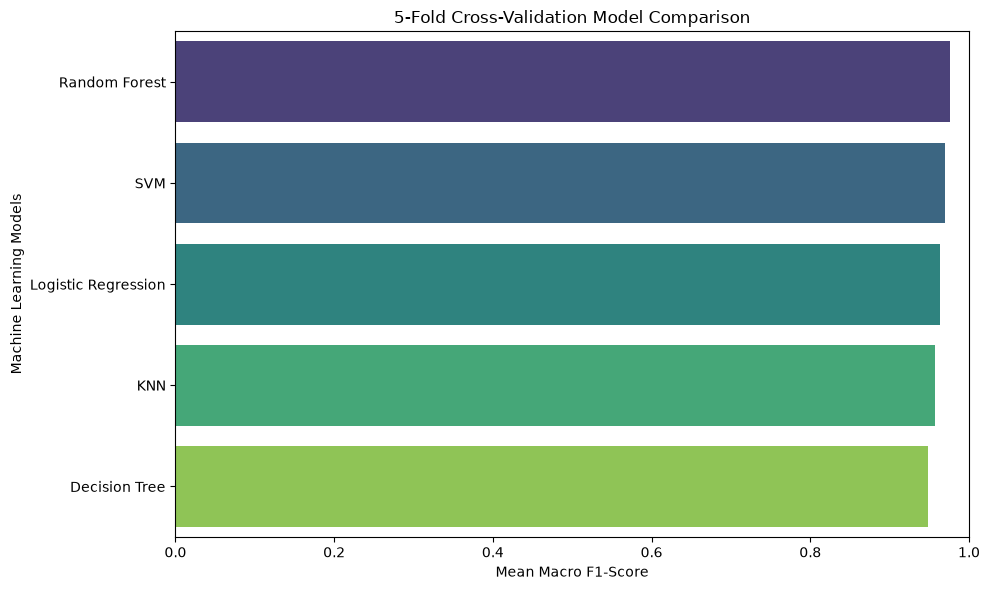

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_results_df.sort_values(
        "Mean_F1",
        ascending=False
    ),
    x="Mean_F1",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("5-Fold Cross-Validation Model Comparison")
plt.xlabel("Mean Macro F1-Score")
plt.ylabel("Machine Learning Models")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [49]:
# Predict using Random Forest

rf_model = trained_models["Random Forest"]

y_pred_rf = rf_model.predict(X_test)

# Classification report

print("Random Forest Classification Report")

print(classification_report(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=[
        "Psoriasis",
        "Seborrheic Dermatitis",
        "Lichen Planus",
        "Pityriasis Rosea",
        "Chronic Dermatitis",
        "Pityriasis Rubra Pilaris"
    ],
    zero_division=0
))

Random Forest Classification Report
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
   Seborrheic Dermatitis       0.90      0.75      0.82        12
           Lichen Planus       1.00      1.00      1.00        15
        Pityriasis Rosea       0.82      0.90      0.86        10
      Chronic Dermatitis       1.00      1.00      1.00        10
Pityriasis Rubra Pilaris       0.80      1.00      0.89         4

                accuracy                           0.95        74
               macro avg       0.92      0.94      0.93        74
            weighted avg       0.95      0.95      0.95        74



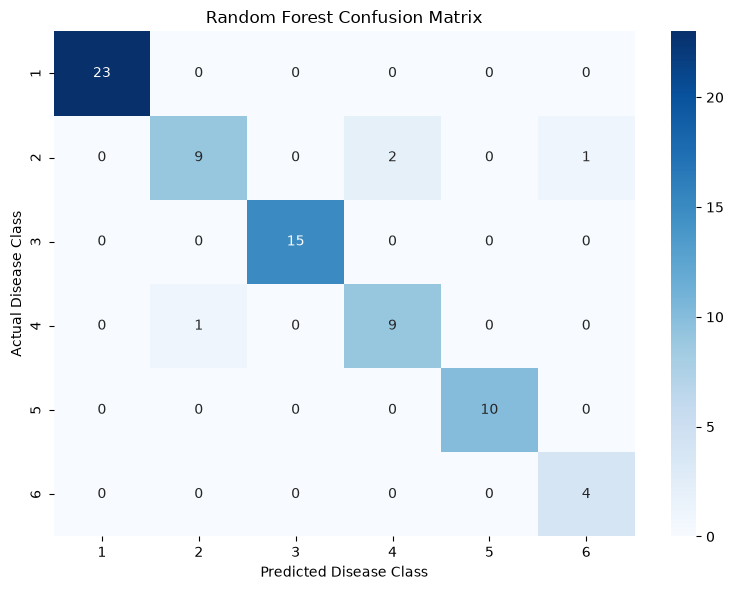

In [50]:
plt.figure(figsize=(8, 6))

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4, 5, 6]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Disease Class")
plt.ylabel("Actual Disease Class")

plt.tight_layout()
plt.show()

In [51]:
from sklearn.metrics import recall_score

class_recall = recall_score(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4, 5, 6],
    average=None
)

recall_table = pd.DataFrame({
    "Disease Class": [
        "Psoriasis",
        "Seborrheic Dermatitis",
        "Lichen Planus",
        "Pityriasis Rosea",
        "Chronic Dermatitis",
        "Pityriasis Rubra Pilaris"
    ],
    "Recall": class_recall
})

display(recall_table.round(4))

,Disease Class,Recall
0,Psoriasis,1.00
1,Seborrheic Dermatitis,0.75
2,Lichen Planus,1.00
3,Pityriasis Rosea,0.90
4,Chronic Dermatitis,1.00
5,Pityriasis Rubra Pilaris,1.00


In [52]:
final_comparison = model_results.merge(
    cv_results_df,
    on="Model"
)

final_comparison = final_comparison.sort_values(
    by="Mean_F1",
    ascending=False
)

display(final_comparison.round(4))

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Mean_F1,Std_F1
2,Random Forest,0.9459,0.9197,0.9417,0.9274,0.9763,0.0107
4,SVM,0.9730,0.9722,0.9722,0.9697,0.9703,0.0183
0,Logistic Regression,0.9595,0.9615,0.9611,0.9574,0.9634,0.0185
3,KNN,0.9054,0.9071,0.9094,0.9034,0.9570,0.0218
1,Decision Tree,0.9595,0.9364,0.9611,0.9447,0.9489,0.0123


In [53]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create Random Forest pipeline

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Define hyperparameter combinations

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

# Stratified cross-validation

cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_tuning,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation Macro F1:
0.977


In [54]:
# Retrieve best tuned model

best_rf_model = grid_search.best_estimator_

# Predict on untouched test data

y_pred_tuned = best_rf_model.predict(X_test)

# Evaluate performance

print("Tuned Random Forest Performance")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("Precision:",
      round(precision_score(
          y_test, y_pred_tuned,
          average="macro",
          zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, y_pred_tuned,
          average="macro",
          zero_division=0
      ), 4))

print("Macro F1-score:",
      round(f1_score(
          y_test, y_pred_tuned,
          average="macro",
          zero_division=0
      ), 4))

Tuned Random Forest Performance
Accuracy: 0.973
Precision: 0.9694
Recall: 0.9694
Macro F1-score: 0.9694


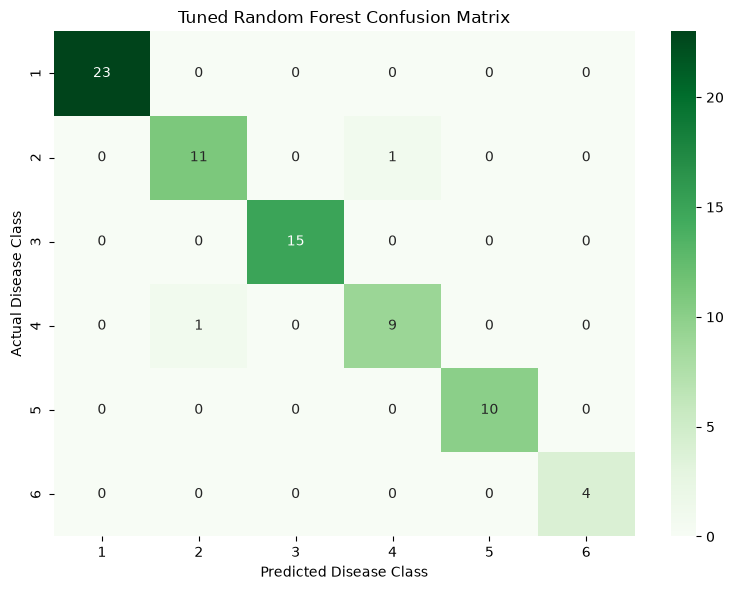

In [55]:
plt.figure(figsize=(8, 6))

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=[1, 2, 3, 4, 5, 6]
)

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.xlabel("Predicted Disease Class")
plt.ylabel("Actual Disease Class")

plt.tight_layout()
plt.show()

In [56]:
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_tuned, average="macro")
    ],
    "Macro Recall": [
        recall_score(y_test, y_pred_rf, average="macro"),
        recall_score(y_test, y_pred_tuned, average="macro")
    ]
})

display(comparison.round(4))

,Model,Accuracy,Macro F1,Macro Recall
0,Original Random Forest,0.9459,0.9274,0.9417
1,Tuned Random Forest,0.9730,0.9694,0.9694


In [57]:
# Extract the tuned Random Forest estimator

rf_estimator = best_rf_model.named_steps["model"]

# Calculate feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_estimator.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance)

,Feature,Importance
0,fibrosis_of_the_papillary_dermis,0.102426
1,koebner_phenomenon,0.065877
2,perifollicular_parakeratosis,0.064585
3,clubbing_of_the_rete_ridges,0.062217
4,follicular_horn_plug,0.060344
5,thinning_of_the_suprapapillary_epidermis,0.054743
6,spongiosis,0.050363
7,elongation_of_the_rete_ridges,0.045984
8,vacuolisation_and_damage_of_basal_layer,0.043027
9,PNL_infiltrate,0.039844


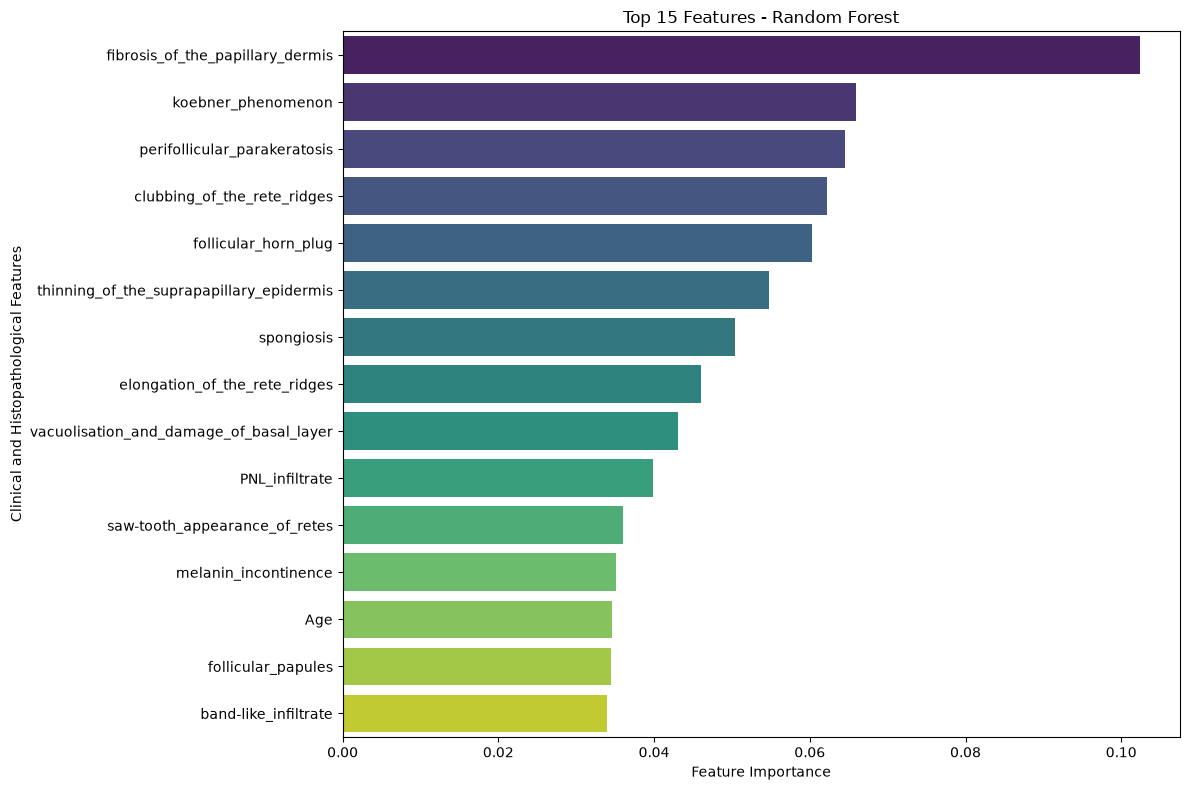

In [58]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Clinical and Histopathological Features")

plt.tight_layout()
plt.show()

In [59]:
top_10_features = feature_importance.head(10)

print("Top 10 Important Features:")

display(top_10_features)

Top 10 Important Features:


,Feature,Importance
0,fibrosis_of_the_papillary_dermis,0.102426
1,koebner_phenomenon,0.065877
2,perifollicular_parakeratosis,0.064585
3,clubbing_of_the_rete_ridges,0.062217
4,follicular_horn_plug,0.060344
5,thinning_of_the_suprapapillary_epidermis,0.054743
6,spongiosis,0.050363
7,elongation_of_the_rete_ridges,0.045984
8,vacuolisation_and_damage_of_basal_layer,0.043027
9,PNL_infiltrate,0.039844


In [60]:
import joblib
import os

# Create output folder if necessary
os.makedirs("Outputs", exist_ok=True)

# Save the tuned Random Forest model
joblib.dump(
    best_rf_model,
    "Outputs/skin_disorder_random_forest.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [61]:
print(os.listdir("Outputs"))

['skin_disorder_random_forest.pkl']


In [62]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDisease Classes:")
print(sorted(df["class"].unique()))

print("\nTotal Patients:", len(df))

Final Dataset Shape: (366, 35)

Missing Values:
8

Disease Classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Total Patients: 366


In [63]:
import os

model_path = "Outputs/skin_disorder_random_forest.pkl"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size:",
          round(os.path.getsize(model_path) / 1024, 2),
          "KB")

Model exists: True
Model size: 957.55 KB


In [64]:
import joblib

loaded_model = joblib.load(
    "Outputs/skin_disorder_random_forest.pkl"
)

print("Model loaded successfully!")

print("Test predictions:",
      loaded_model.predict(X_test.head(5)))

Model loaded successfully!
Test predictions: [2 3 4 1 4]


In [65]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", round(grid_search.best_score_, 4))
print("Tuned Test Accuracy:", round(
    best_rf_model.score(X_test, y_test), 4))

Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV Macro F1: 0.977
Tuned Test Accuracy: 0.973


In [66]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_tuned = best_rf_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.92      0.92      0.92        12
           3       1.00      1.00      1.00        15
           4       0.90      0.90      0.90        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.97      0.97      0.97        74

Confusion Matrix:
[[23  0  0  0  0  0]
 [ 0 11  0  1  0  0]
 [ 0  0 15  0  0  0]
 [ 0  1  0  9  0  0]
 [ 0  0  0  0 10  0]
 [ 0  0  0  0  0  4]]


                                     Feature  Importance
14          fibrosis_of_the_papillary_dermis    0.102426
4                         koebner_phenomenon    0.065877
30              perifollicular_parakeratosis    0.064585
19               clubbing_of_the_rete_ridges    0.062217
29                      follicular_horn_plug    0.060344
21  thinning_of_the_suprapapillary_epidermis    0.054743
27                                spongiosis    0.050363
20             elongation_of_the_rete_ridges    0.045984
26   vacuolisation_and_damage_of_basal_layer    0.043027
13                            PNL_infiltrate    0.039844
28             saw-tooth_appearance_of_retes    0.036004
11                      melanin_incontinence    0.035175
33                                       Age    0.034589
6                         follicular_papules    0.034450
32                      band-like_infiltrate    0.033927


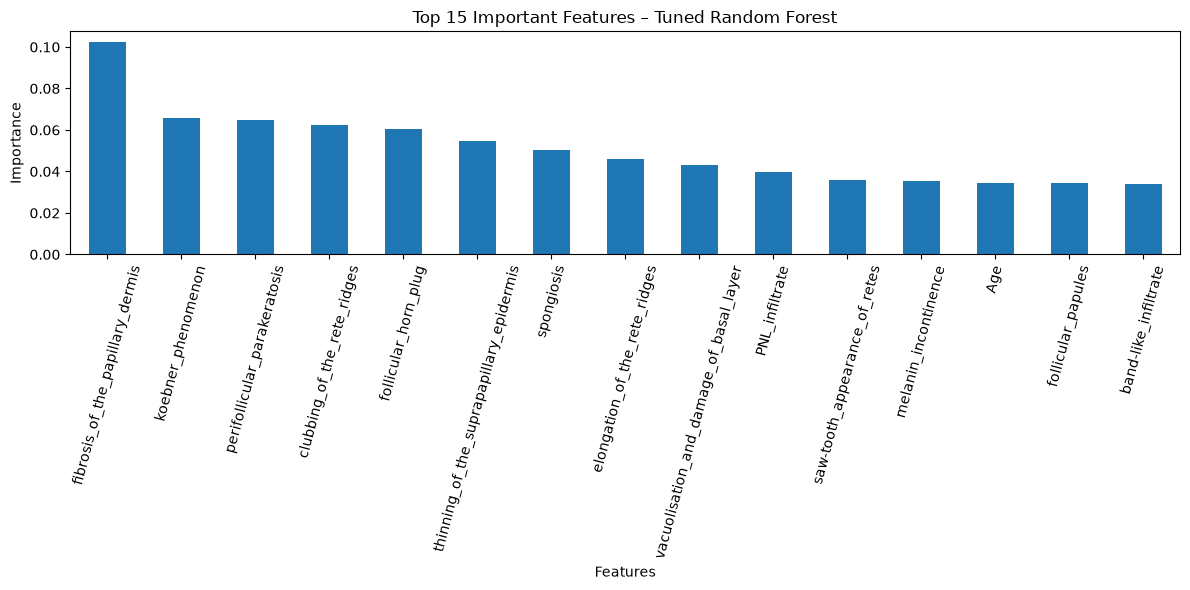

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

importance = best_rf_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance.head(15))

feature_importance.head(15).plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(12, 6),
    legend=False
)

plt.title("Top 15 Important Features – Tuned Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [68]:
import joblib

joblib.dump(
    best_rf_model,
    "Outputs/skin_disorder_random_forest.pkl"
)

print("Tuned Random Forest model saved successfully!")

Tuned Random Forest model saved successfully!


In [69]:
import os

print("Project folder contents:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]
    for file in files:
        print(os.path.join(root, file))

Project folder contents:
./.DS_Store
./PRCP_1027_Skin_Disorder_Prediction.ipynb.zip
./PRCP_1027_Skin_Disorder_Prediction.ipynb
./anaconda_projects/.DS_Store
./anaconda_projects/db/project_filebrowser.db
./Dataset/PRCP-1028-Skin-Disorder-Prediction-20220512T101734Z-001.zip
./Dataset/.DS_Store
./Dataset/PRCP-1028-Skin-Disorder-Prediction/dataset_35_dermatology (1).csv
./Outputs/skin_disorder_random_forest.pkl


## Doctor Recommendations for Early Identification of Skin Diseases

The developed machine learning model can assist healthcare professionals
in the preliminary classification of six types of skin disorders:
Psoriasis, Seborrheic Dermatitis, Lichen Planus, Pityriasis Rosea,
Chronic Dermatitis and Pityriasis Rubra Pilaris.

The following recommendations may help doctors in the early identification
and differentiation of these skin diseases.

1. Clinical Examination:
   Doctors should carefully examine clinical features such as erythema,
   scaling, itching, definite borders, Koebner phenomenon and the
   involvement of specific body regions.

2. Histopathological Examination:
   When clinical findings are insufficient, skin biopsy and microscopic
   examination should be considered to identify characteristic
   histopathological features.

3. Patient Medical History:
   Patient age, family history, disease progression and previous
   dermatological conditions should be considered during diagnosis.

4. Identification of Characteristic Features:
   Doctors should pay attention to features such as clubbing of rete ridges,
   fibrosis of the papillary dermis, spongiosis, melanin incontinence
   and perifollicular parakeratosis.

5. Use of Machine Learning:
   The developed Random Forest model may be explored as a decision-support
   tool to assist in classifying dermatological conditions based on
   clinical and histopathological attributes.

6. Early Referral:
   Patients with persistent, progressive or unclear skin lesions should
   be referred to a dermatologist for further evaluation.

7. Continuous Monitoring:
   Patients should be monitored regularly to evaluate disease progression
   and response to treatment.

Note:
The machine learning model is intended only as a supportive research tool.
It should not replace professional dermatological examination, clinical
judgment or appropriate diagnostic investigations.

## Challenges Faced During the Project

Several challenges were encountered during data analysis, preprocessing
and machine learning model development.

1. Missing Values:
   The Age attribute contained missing values.
   Technique Used: Median imputation was applied to handle missing values
   because the median is less affected by extreme observations than the mean.

2. Data Type Conversion:
   Some dataset attributes were initially loaded with incorrect data types.
   Technique Used: Pandas numeric conversion was performed to ensure
   appropriate numerical representation of the features.

3. Dataset Understanding:
   Understanding the clinical and histopathological attributes was
   challenging because several features are associated with similar
   dermatological conditions.
   Technique Used: Attribute descriptions were studied to understand
   the biological and clinical significance of the variables.

4. Class Imbalance:
   The dataset contained unequal numbers of observations across the
   six disease classes.
   Technique Used: Stratified train-test splitting was used to maintain
   class proportions. Class weighting was also explored in selected models.

5. Model Selection:
   Identifying the most suitable machine learning algorithm was challenging.
   Technique Used: Five algorithms were evaluated: Logistic Regression,
   Decision Tree, Random Forest, K-Nearest Neighbors and Support Vector Machine.

6. Model Optimization:
   Initial model performance could be improved through parameter selection.
   Technique Used: GridSearchCV with stratified cross-validation was used
   to identify suitable Random Forest hyperparameters.

7. Model Evaluation:
   Accuracy alone was insufficient to understand performance across
   all disease classes.
   Technique Used: Precision, recall, F1-score, confusion matrix and
   cross-validation were used for model evaluation.

## Limitations of the Project

1. The dataset contains only 366 observations, which may limit the
   generalizability of the developed model.

2. The dataset contains six disease classes with unequal sample sizes.

3. Missing values were present in the Age attribute and required
   imputation during preprocessing.

4. The model was evaluated using a single train-test split, so
   performance may vary with different data partitions.

5. The dataset contains predefined clinical and histopathological
   attributes and does not include direct analysis of skin images.

6. The model has not been validated using an independent external
   clinical dataset.

7. Feature importance indicates predictive contribution but does not
   establish a causal relationship between a feature and a disease.

8. The model should not be considered a standalone diagnostic system
   or used to make treatment decisions.

## Future Scope

1. Dataset Expansion:
   The model can be trained using larger and more diverse dermatological
   datasets to improve its generalizability.

2. External Validation:
   The developed model can be evaluated using independent datasets
   collected from different hospitals and patient populations.

3. Advanced Machine Learning Algorithms:
   Additional algorithms such as XGBoost, Gradient Boosting and
   other ensemble learning techniques can be explored.

4. Explainable Artificial Intelligence:
   Techniques such as SHAP and LIME can be incorporated to improve
   the interpretability of model predictions.

5. Image-Based Classification:
   Dermatological images can be integrated with clinical and
   histopathological attributes to explore multimodal classification.

6. Application Development:
   A user-friendly application can be developed to support
   dermatological research and educational purposes.

7. Clinical Collaboration:
   Collaboration with dermatologists can help evaluate the model's
   practical relevance and identify opportunities for improvement.

8. Continuous Model Improvement:
   Regular evaluation and retraining using validated datasets may
   help maintain model performance over time.